<a href="https://colab.research.google.com/github/yibesh/DeepLearning/blob/main/Deep_Learning_Overfitting_and_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep_Learning_Overfitting_and_Regularization


### Real IoT Sensor Data → MLP → Overfitting → Regularization

**Learning goals**

By the end of this laboratory, you will be able to:

1. Load a real IoT sensor dataset.
2. Visualize sensor measurements.
3. Prepare time-series data.
4. Build a simple neural network using `Dense`.
5. Understand overfitting.
6. Use Dropout, L2 regularization, and Early Stopping.
7. Compare model performance.

**Dataset:** UCI Occupancy Detection  
**Target:** 0 = Not occupied, 1 = Occupied

In [4]:
# 1. Import libraries

!pip -q install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

from ucimlrepo import fetch_ucirepo

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load the real IoT dataset

The sensors measure:

- Temperature
- Humidity
- Light
- CO₂
- Humidity Ratio

The target is room occupancy.

In [5]:
# Load UCI Occupancy Detection dataset

data = fetch_ucirepo(id=357)

X = data.data.features.copy()
y = data.data.targets.copy()

df = pd.concat([X, y], axis=1)

# Convert date, turning invalid header rows into NaT, then dropping them
df["date"] = pd.to_datetime(df["date"], errors='coerce')
df = df.dropna(subset=["date"])
df = df.sort_values("date").reset_index(drop=True)

print("Number of samples:", len(df))
display(df.head())

Number of samples: 20560


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7,26.272,585.2,749.2,0.00476416302416414,1.0
1,2015-02-02 14:19:59,23.718,26.29,578.4,760.4,0.00477266099212519,1.0
2,2015-02-02 14:21:00,23.73,26.23,572.666666666667,769.666666666667,0.00476515255246541,1.0
3,2015-02-02 14:22:00,23.7225,26.125,493.75,774.75,0.00474377335599685,1.0
4,2015-02-02 14:23:00,23.754,26.2,488.6,779,0.00476659399998615,1.0


In [6]:
# Look at the sensor data

print(df[["Temperature", "Humidity", "Light", "CO2", "Occupancy"]].describe())

          Occupancy
count  20560.000000
mean       0.231031
std        0.421503
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000


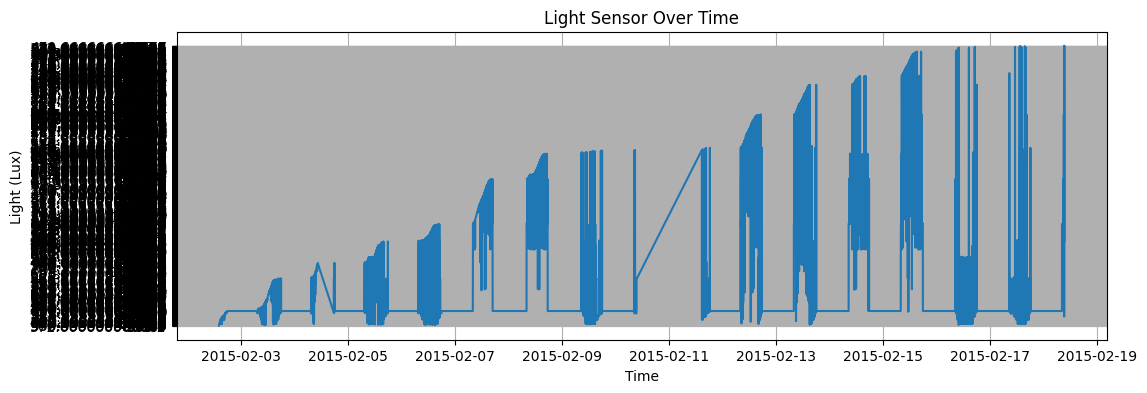

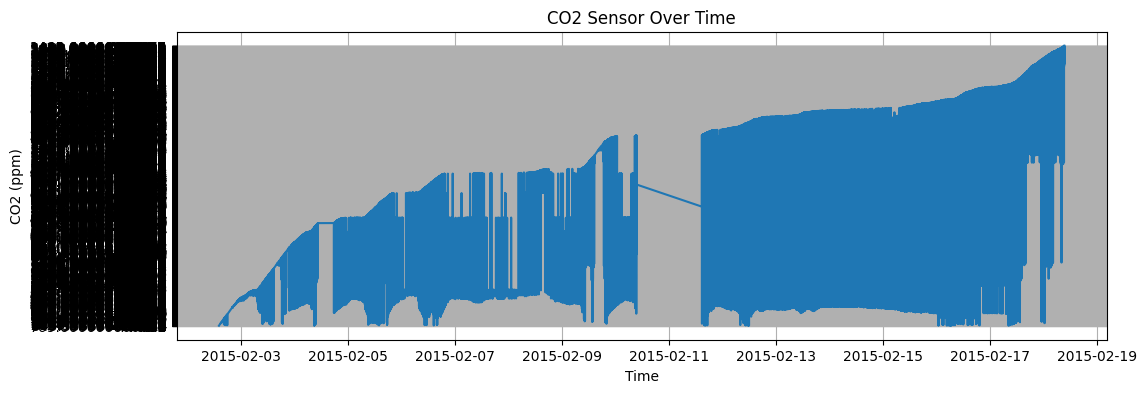

In [7]:
# Visualize two IoT sensor signals

plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["Light"])
plt.xlabel("Time")
plt.ylabel("Light (Lux)")
plt.title("Light Sensor Over Time")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["CO2"])
plt.xlabel("Time")
plt.ylabel("CO2 (ppm)")
plt.title("CO2 Sensor Over Time")
plt.grid()
plt.show()

# 3. Split the time series

Because this is time-series data, we **do not randomly shuffle the observations**.

We use:

- First 70% → Training
- Next 15% → Validation
- Last 15% → Test

The model therefore learns from earlier observations and is evaluated on later observations.

In [8]:
features = [
    "Temperature",
    "Humidity",
    "Light",
    "CO2",
    "HumidityRatio"
]

X = df[features].values
y = df["Occupancy"].values.astype(int)

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X[:train_end]
y_train = y[:train_end]

X_val = X[train_end:val_end]
y_val = y[train_end:val_end]

X_test = X[val_end:]
y_test = y[val_end:]

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Training: 14391
Validation: 3085
Test: 3084


# 4. Normalize the sensor values

The sensors have very different numerical ranges.

We use standardization:

\[
x_{new} = rac{x-\mu}{\sigma}
\]

The scaler is fitted using **training data only**.

In [9]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Sensor data normalized.")

Sensor data normalized.


# 5. Create simple time windows

We use the previous **12 measurements** to predict occupancy.

Each input contains:

**12 time steps × 5 sensor features**

So the neural network receives recent sensor history rather than only one measurement.

In [10]:
window = 12

def make_windows(X, y):
    X_new = []
    y_new = []

    for i in range(window, len(X)):
        X_new.append(X[i-window:i])
        y_new.append(y[i])

    return np.array(X_new), np.array(y_new)

X_train, y_train = make_windows(X_train, y_train)
X_val, y_val = make_windows(X_val, y_val)
X_test, y_test = make_windows(X_test, y_test)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Training shape: (14379, 12, 5)
Validation shape: (3073, 12, 5)
Test shape: (3072, 12, 5)


# 6. Build the baseline MLP

We will use the simple Keras style:

```python
model = Sequential()

model.add(Flatten(input_shape=(12, 5)))
model.add(Dense(32, activation="relu"))
model.add(Dense(16, activation="relu"))
model.add(Dense(1, activation="sigmoid"))
```

### Network

```text
12 × 5 sensor values
        ↓
     Flatten
        ↓
     Dense(32)
        ↓
     Dense(16)
        ↓
     Dense(1)
        ↓
    Occupancy
```

`sigmoid` is used because this is a binary classification problem.

In [11]:
# Build the baseline neural network

model = Sequential()

model.add(Flatten(input_shape=(12, 5)))
model.add(Dense(32, activation="relu"))
model.add(Dense(16, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 60)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,497 (9.75 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Train the baseline model

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Epoch 1/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9714 - loss: 0.0974 - val_accuracy: 0.9557 - val_loss: 0.0750
Epoch 2/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9831 - loss: 0.0607 - val_accuracy: 0.9476 - val_loss: 0.1023
Epoch 3/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9846 - loss: 0.0551 - val_accuracy: 0.9466 - val_loss: 0.1145
Epoch 4/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9850 - loss: 0.0521 - val_accuracy: 0.9470 - val_loss: 0.1226
Epoch 5/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9853 - loss: 0.0498 - val_accuracy: 0.9437 - val_loss: 0.1377
Epoch 6/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9857 - loss: 0.0481 - val_accuracy: 0.9457 - val_loss: 0.1324
Epoch 7/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9860 - loss: 0.0471 - val_accuracy: 0.9440 - val_loss: 0.1418
Epoch 8/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9864 - loss: 0.0461 - val_accuracy: 0.

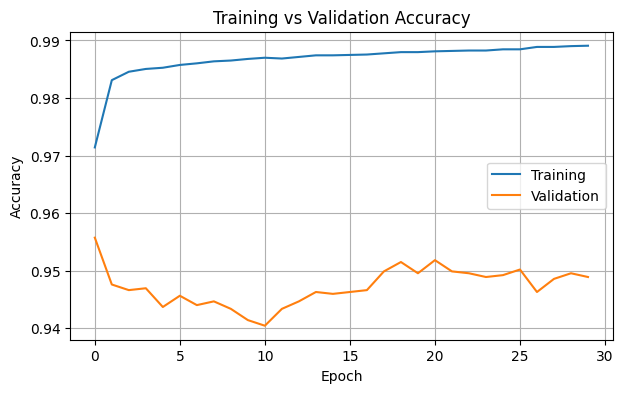

In [13]:
# Training and validation accuracy

plt.figure(figsize=(7, 4))

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

# 7. Observe overfitting

Look at the training and validation curves.

### Possible sign of overfitting

Training performance continues to improve while validation performance stops improving or becomes worse.

**Question:**  
Why can a neural network perform very well on training data but worse on unseen data?

# 8. Dropout

Dropout randomly turns off some neurons during training.

Here we use:

**Dropout = 30%**

The goal is to reduce overfitting and improve generalization.

In [14]:
# Build a neural network with Dropout

dropout_model = Sequential()

dropout_model.add(Flatten(input_shape=(12, 5)))
dropout_model.add(Dense(32, activation="relu"))
dropout_model.add(Dropout(0.3))
dropout_model.add(Dense(16, activation="relu"))
dropout_model.add(Dropout(0.3))
dropout_model.add(Dense(1, activation="sigmoid"))

dropout_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

dropout_history = dropout_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Epoch 1/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9539 - loss: 0.1553 - val_accuracy: 0.9818 - val_loss: 0.0352
Epoch 2/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9814 - loss: 0.0806 - val_accuracy: 0.9772 - val_loss: 0.0411
Epoch 3/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9824 - loss: 0.0727 - val_accuracy: 0.9652 - val_loss: 0.0646
Epoch 4/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9841 - loss: 0.0709 - val_accuracy: 0.9730 - val_loss: 0.0538
Epoch 5/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9838 - loss: 0.0669 - val_accuracy: 0.9626 - val_loss: 0.0700
Epoch 6/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9846 - loss: 0.0655 - val_accuracy: 0.9590 - val_loss: 0.0769
Epoch 7/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9841 - loss: 0.0666 - val_accuracy: 0.9616 - val_loss: 0.0670
Epoch 8/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9850 - loss: 0.0640 - val_accuracy: 0.

# 9. L2 Regularization

L2 regularization adds a penalty for large weights.

The idea is:

> Encourage the neural network to learn simpler patterns instead of relying on very large weights.

We use:

**L2 = 0.001**

In [15]:
# Build a neural network with L2 regularization

l2_model = Sequential()

l2_model.add(Flatten(input_shape=(12, 5)))

l2_model.add(Dense(
    32,
    activation="relu",
    kernel_regularizer=l2(0.001)
))

l2_model.add(Dense(
    16,
    activation="relu",
    kernel_regularizer=l2(0.001)
))

l2_model.add(Dense(1, activation="sigmoid"))

l2_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

l2_history = l2_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32
)

Epoch 1/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9713 - loss: 0.1597 - val_accuracy: 0.9610 - val_loss: 0.1113
Epoch 2/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9828 - loss: 0.1045 - val_accuracy: 0.9587 - val_loss: 0.1105
Epoch 3/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9844 - loss: 0.0890 - val_accuracy: 0.9583 - val_loss: 0.1059
Epoch 4/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9849 - loss: 0.0794 - val_accuracy: 0.9600 - val_loss: 0.0992
Epoch 5/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9851 - loss: 0.0730 - val_accuracy: 0.9587 - val_loss: 0.0988
Epoch 6/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9853 - loss: 0.0687 - val_accuracy: 0.9570 - val_loss: 0.1004
Epoch 7/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9855 - loss: 0.0655 - val_accuracy: 0.9570 - val_loss: 0.1022
Epoch 8/30
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9857 - loss: 0.0630 - val_accuracy: 0.

# 10. Early Stopping

Early stopping stops training when validation performance stops improving.

Instead of deciding exactly how many epochs are needed, we allow the model to stop automatically.

Here:

- Monitor: validation loss
- Patience: 5 epochs
- Restore the best model weights

In [16]:
# Build a simple neural network

early_model = Sequential()

early_model.add(Flatten(input_shape=(12, 5)))
early_model.add(Dense(32, activation="relu"))
early_model.add(Dense(16, activation="relu"))
early_model.add(Dense(1, activation="sigmoid"))

early_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

early_history = early_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/50
450/450 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9736 - loss: 0.0999 - val_accuracy: 0.9629 - val_loss: 0.0691
Epoch 2/50
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9839 - loss: 0.0593 - val_accuracy: 0.9570 - val_loss: 0.0940
Epoch 3/50
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9848 - loss: 0.0548 - val_accuracy: 0.9557 - val_loss: 0.0956
Epoch 4/50
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9854 - loss: 0.0520 - val_accuracy: 0.9551 - val_loss: 0.0979
Epoch 5/50
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9856 - loss: 0.0500 - val_accuracy: 0.9551 - val_loss: 0.0973
Epoch 6/50
450/450 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9859 - loss: 0.0481 - val_accuracy: 0.9554 - val_loss: 0.0981


# 11. Compare the models

We compare:

1. Baseline
2. Dropout
3. L2 regularization
4. Early Stopping

The **test set is used only for final evaluation**.

In [17]:
models = {
    "Baseline": model,
    "Dropout": dropout_model,
    "L2": l2_model,
    "Early Stopping": early_model
}

results = []

for name, current_model in models.items():

    probability = current_model.predict(
        X_test,
        verbose=0
    ).ravel()

    prediction = (probability >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(
            y_test, prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_test, prediction, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, prediction, zero_division=0
        )
    })

results = pd.DataFrame(results)

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline,0.991,0.976,0.999,0.987
1,Dropout,0.993,0.984,0.998,0.991
2,L2,0.993,0.984,0.996,0.990
3,Early Stopping,0.990,0.979,0.993,0.986


# 12. Confusion Matrix

A confusion matrix shows four types of predictions:

- **True Negative:** correctly predicted not occupied
- **True Positive:** correctly predicted occupied
- **False Positive:** predicted occupied, but actually not occupied
- **False Negative:** predicted not occupied, but actually occupied

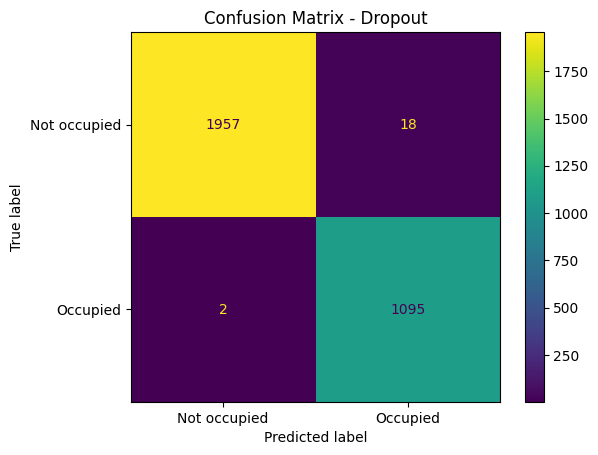

Best model: Dropout


In [18]:
# Find the model with the best F1-score

best_name = results.sort_values(
    "F1-score",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_name]

probability = best_model.predict(
    X_test,
    verbose=0
).ravel()

prediction = (probability >= 0.5).astype(int)

cm = confusion_matrix(y_test, prediction)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not occupied", "Occupied"]
).plot()

plt.title("Confusion Matrix - " + best_name)
plt.show()

print("Best model:", best_name)

# 13. Mini Challenge

Change **only one parameter** and observe what happens.

### Option A — Window size

```text
12 → 6
12 → 30
```

### Option B — Dropout

```text
0.3 → 0.1
0.3 → 0.5
```

### Option C — Number of neurons

```text
Dense(32) → Dense(64)
```

### Option D — Training epochs

```text
30 → 60
```

Record:

- Accuracy
- Precision
- Recall
- F1-score

Then explain why the result changed.

---

# Final takeaway

```text
Real IoT Data
      ↓
Time-Series Preparation
      ↓
Simple Dense Neural Network
      ↓
Overfitting
      ↓
Regularization
      ↓
Better Generalization
```

> **Deep learning is not about memorizing the training data.  
> It is about learning useful patterns that work on unseen data.**